## **Lab 3: Spectral Representation**

The goal of this lab is to connect the time-domain signal you have been working with to its frequency-domain representation. The theory summary on spectrum representation introduces two complementary views of the same signal:

- the Fourier transform, which gives the frequency content of a signal segment, and
- the spectrogram, which shows how that content changes over time.

In this lab we will first compute the magnitude spectrum of a short fragment of the reference audio, then we will compute a spectrogram of the whole sound. The goal is not only to produce plots, but also to interpret them and relate them back to the sound you hear.

A periodic signal contains energy at its fundamental frequency and at its harmonics. When the signal is not perfectly periodic, the spectrum becomes less sharp and the energy spreads around those frequencies. In a short fragment, the FFT gives a snapshot of the dominant components. In a longer signal, the spectrogram shows how these components evolve over time.

In [1]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display

from util import load_audio, plot_signals, plot_spectrogram, plot_spectrum

We will use the same reference sound from the previous labs. If you have your own audio file in a cloned repository, you can point the path there; otherwise the notebook will use the bundled reference file.

### 1. Spectrum Analysis

This section show how to compute the spectrum and the spectrogram of a sound

In [3]:
# Clone your own repository and point reference_path to your own audio file.
# \!git clone https://github.com/your-username/sis1_name.git
# reference_path = Path('./sis1_name/your_file.wav')

reference_path = Path('audio_lab1.wav')
reference_audio, fs = load_audio(reference_path)
print(f'Using audio file: {reference_path}')

display(Audio(reference_audio, rate=fs))

Using audio file: audio_lab1.wav


#### 1.1 Fourier transform of a short fragment

The first step is to look at a short fragment of the sound and compute its magnitude spectrum using the FFT. This gives a snapshot of the strongest frequency components present in that fragment.

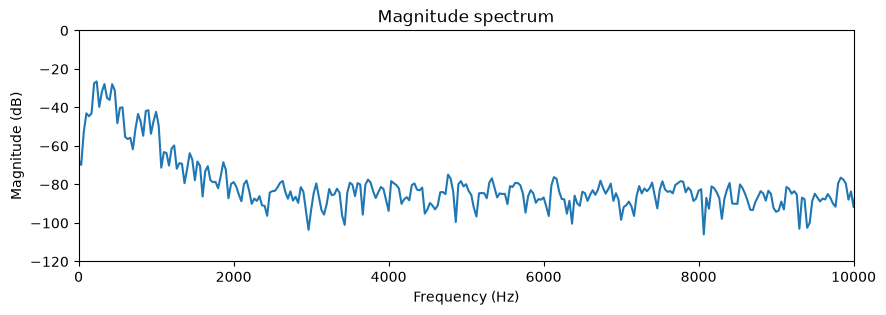

In [4]:
start = int(0.25 * fs)
end = int(0.28 * fs)
fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

#### 1.2 Questions

1. What are the strongest peaks in the magnitude spectrum? To what harmonics do they correspond?
   - The strongest peak that we can observe corresponds to the fundamental frequency, also other peaks that we can observe appear aproximetly at the multiples of the fundamnetal frequency ( corrsponding to the first, second, third, fourth... harmonics)

2. Do you see a fundamental frequency and its harmonics? How did you identify them?
   - Yes, the fundamental frequency and its harmonics are clearly visible as a sequence of regularly spaced sharp peaks.

3. How would the spectrum change if the fragment were taken from a different part of the signal?
   - f taken from a later part during the decay phase, the overall peak amplitudes would be lower in dB, and high-frequency harmonic peaks would drop faster than the fundamental peak.

#### 1.3 Spectrogram of the whole sound

The FFT of one fragment gives a local snapshot, but a sound changes over time. A spectrogram shows how the frequency content evolves across the whole signal.

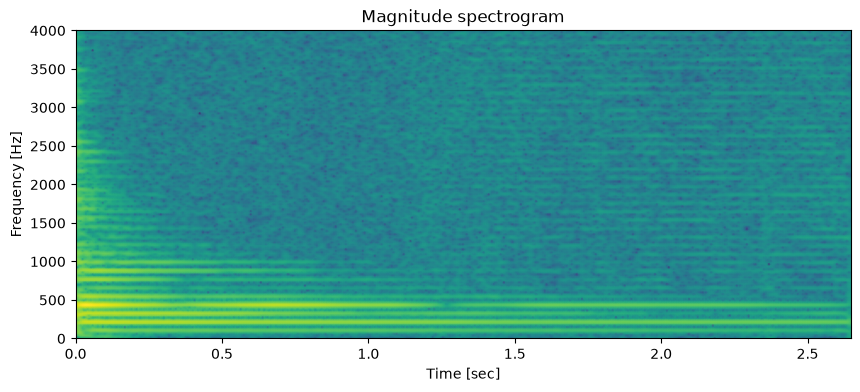

In [5]:
n_fft = 2048
hop_length = 256

ax = plot_spectrogram(reference_audio, sr=fs, N=n_fft, H=hop_length)
ax.set_ylim([0, 4000])
plt.show()

#### 1.4 Questions

1. Which frequencies are present for most of the sound? What does it mean from a perceptual point of view?
   - The lowest frequencies (below 500 Hz, shown as the bright lines at the bottom) stay present for the full 2.5 seconds. Perceptually, this means you hear the exact same pitch (note A2) from start to finish

2. Do the bright bands stay fixed or do they change over time? What does it mean?
   - The lines stay at the exact same height, which means the pitch never changes. However, the lines fade and get darker over time, meaning the sound is losing energy and getting quieter

3. How does the spectrogram help explain why the sound changes over time? Describe the sound evolution.
   - It shows that the sound starts with a sharp pluck containing high frequencies up to 3000 Hz. Those high frequencies die out quickly in under a second, leaving only the low frequencies. This explains why the sound changes from a bright, noisy pluck at the beginning to a soft, dull tone as it fades out

#### 1.4 Fragment comparison

Repeat the spectral analysis for a different fragment of the signal and compare the magnitude spectra. Explain the difference.

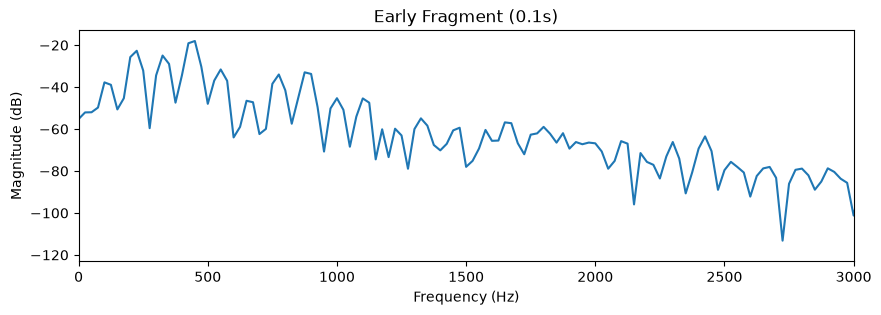

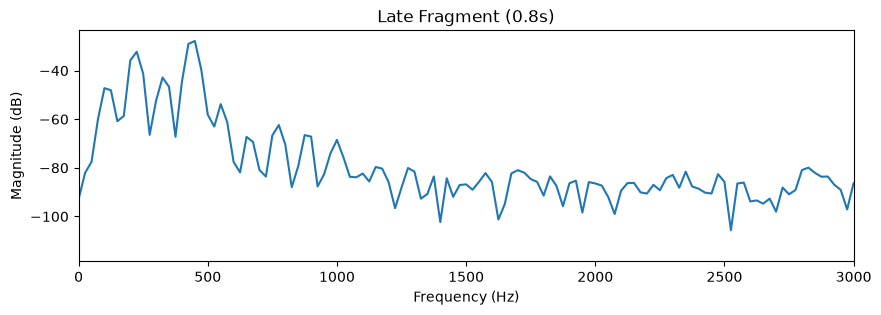

In [6]:
frag1 = reference_audio[int(0.1 * fs):int(0.14 * fs)]
ax1 = plot_spectrum(frag1, sr=fs)
ax1.set_xlim([0, 3000])
ax1.set_title("Early Fragment (0.1s)")
plt.show()

frag2 = reference_audio[int(0.8 * fs):int(0.84 * fs)]
ax2 = plot_spectrum(frag2, sr=fs)
ax2.set_xlim([0, 3000])
ax2.set_title("Late Fragment (0.8s)")
plt.show()

- Comparing the early (0.1 s) and late (0.8 s) fragments shows an overall drop in vibration energy, with peak magnitudes falling from around −18 dB to −27 dB. High-frequency harmonics above 1000 Hz die out rapidly into the noise floor below −80 dB, while the low frequencies below 500 Hz persist much longer as the strongest peaks. Perceptually, this proves that as the plucked string decays over time, it gets quieter and loses its initial sharp brightness, resulting in a duller, warmer tone. 

Choose a time where several harmonics are visible in the spectrogram and plot the spectrum at that time. Can you explain the result?

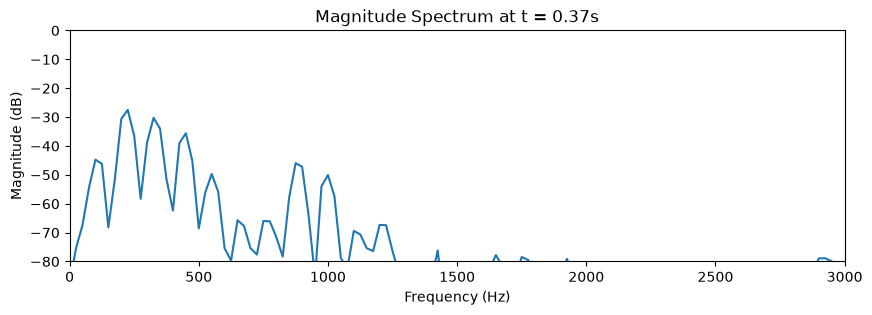

In [7]:
start_time = 0.37
duration = 0.04  
fragment_chosen = reference_audio[int(start_time * fs):int((start_time + duration) * fs)]

ax = plot_spectrum(fragment_chosen, sr=fs)
ax.set_xlim([0, 3000])
ax.set_ylim([-80, 0])
ax.set_title(f'Magnitude Spectrum at t = {start_time}s')
plt.show()

- At t=0.37 s, sharp regularly spaced peaks appear at integer multiples of f0 = 111.1 Hz (222 Hz, 333 Hz, 444 Hz, etc.). This shows that during the steady portion of the note, the sound consists of a fundamental frequency overlaid with several prominent harmonic overtones before they fully decay.

Use the plots to estimate the weights of the fundamental frequency and a few harmonics. Store them in a list for later use. Be careful because the amplitude of the plot are in dB and you will need them in a linear scale, from 0 to 1, where 1 should be the maximum value of the spectrum. So you need to perform the conversion from dB to linear.

In [9]:
db_peaks = np.array([0.0, -4.4, -9.1, -14.0, -20.0])

weights = 10**(db_peaks / 20.0)

weights = list(weights / np.max(weights))

print("Linear spectral weights (Ak):", [round(w, 4) for w in weights]) 

Linear spectral weights (Ak): [np.float64(1.0), np.float64(0.6026), np.float64(0.3508), np.float64(0.1995), np.float64(0.1)]


### 2. Synthesis

Now we will use the harmonic synthesis idea from previous labs to build a signal from the estimated spectral weights.

In [10]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

#### 2.1 Write the code

Use the `synthesize` function to generate a signal with the weights from part 1.3 and the fundamental frequency and phase from earlier labs. Plot the synthesized signal together with the reference so you can compare them directly.

In [15]:
f0 = 111.1
phi = 0.8
t = np.arange(len(reference_audio)) / fs

synthesis = synthesize(f0, phi, weights, t)

synthesis = np.max(np.abs(reference_audio)) * synthesis / np.max(np.abs(synthesis))

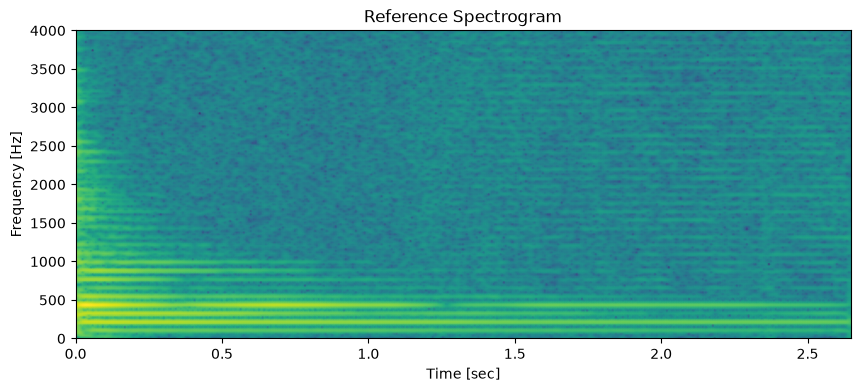

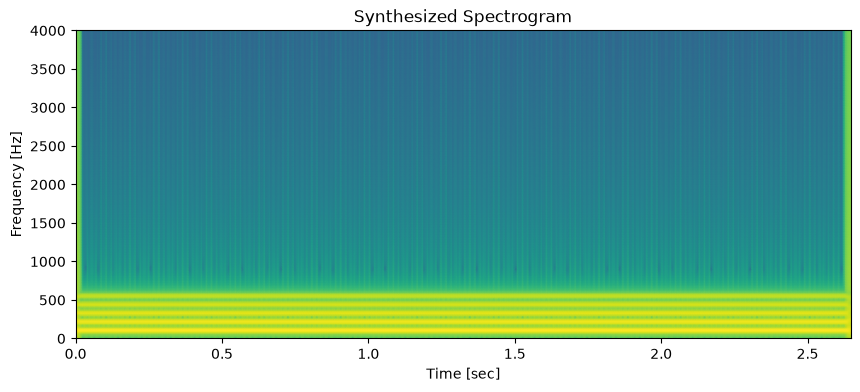

In [17]:
t_start = 0.3705
t_end = t_start + (8 / f0)
plot_signals([reference_audio, synthesis], fs, t_start=t_start, t_end=t_end, name=['reference', 'synthesized'])

ax1 = plot_spectrogram(reference_audio, sr=fs, N=2048, H=256)
ax1.set_title('Reference Spectrogram')
ax1.set_ylim([0, 4000])
plt.show()

ax2 = plot_spectrogram(synthesis, sr=fs, N=2048, H=256)
ax2.set_title('Synthesized Spectrogram')
ax2.set_ylim([0, 4000])
plt.show()

display(Audio(synthesis, rate=fs))

#### 2.2 Questions

1. What do you notice when you compare the synthesized spectrogram with the reference spectrogram?
   - The reference spectrogram shows horizontal harmonic bands that fade and darken over time as the string loses energy. In contrast, the synthesized spectrogram shows completely static, solid horizontal lines that stay equally bright across the entire duration without any fading.

2. Which parts of the sound are reproduced well, and which parts are still missing or different?
   - Reproduced well: The fundamental pitch (111.1 Hz) and the relative harmonic timbre during the steady portion of the note.
   
   - Missing or different: The natural volume decay over time (the synthesized sound does not fade out) and the initial noisy, percussive pluck attack at t=0 s.